<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_080_time_series_train_test_split.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 80/365 — Train/Test Split for Time Series

Yesterday we learned the basics of time-series data.

Today we focus on one critical rule:

> **Never let the future leak into the past.**

For forecasting, training data should come from earlier dates and testing data should come from later dates.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split, TimeSeriesSplit


## 1. Create a synthetic daily-demand series

In [2]:
rng=np.random.default_rng(42)

dates=pd.date_range("2026-01-01", periods=240, freq="D")
t=np.arange(len(dates))

trend=100 + 0.35*t
weekly=10*np.sin(2*np.pi*t/7)
noise=rng.normal(0,4,len(dates))

df=pd.DataFrame({
    "date":dates,
    "demand":trend+weekly+noise
})

df.head()


,date,demand
0,2026-01-01,101.218868
1,2026-01-02,104.008378
2,2026-01-03,113.451084
3,2026-01-04,109.151096
4,2026-01-05,89.257022


## 2. Create lag-based features

We only use information that would already be available at prediction time.


In [3]:
df["lag_1"]=df["demand"].shift(1)
df["lag_7"]=df["demand"].shift(7)

df["rolling_7"]=(
    df["demand"]
    .shift(1)
    .rolling(7)
    .mean()
)

model_df=df.dropna().copy()

features=["lag_1","lag_7","rolling_7"]

X=model_df[features]
y=model_df["demand"]

print("Rows available:",len(model_df))


Rows available: 233


## 3. Random split

This mixes earlier and later dates.

It may be acceptable for ordinary i.i.d. tabular data, but it can create unrealistic evaluation for forecasting.


In [4]:
X_train_rand,X_test_rand,y_train_rand,y_test_rand=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

random_model=LinearRegression()
random_model.fit(X_train_rand,y_train_rand)

random_pred=random_model.predict(X_test_rand)

random_mae=mean_absolute_error(
    y_test_rand,
    random_pred
)

print("Random split MAE:",round(random_mae,3))


Random split MAE: 4.358


## 4. Chronological split

Use the first 80% of dates for training and the most recent 20% for testing.


In [5]:
split_index=int(len(model_df)*0.8)

train=model_df.iloc[:split_index].copy()
test=model_df.iloc[split_index:].copy()

X_train_time=train[features]
y_train_time=train["demand"]

X_test_time=test[features]
y_test_time=test["demand"]

time_model=LinearRegression()
time_model.fit(X_train_time,y_train_time)

time_pred=time_model.predict(X_test_time)

time_mae=mean_absolute_error(
    y_test_time,
    time_pred
)

print("Chronological split MAE:",round(time_mae,3))


Chronological split MAE: 3.513


## 5. Visualize the correct split

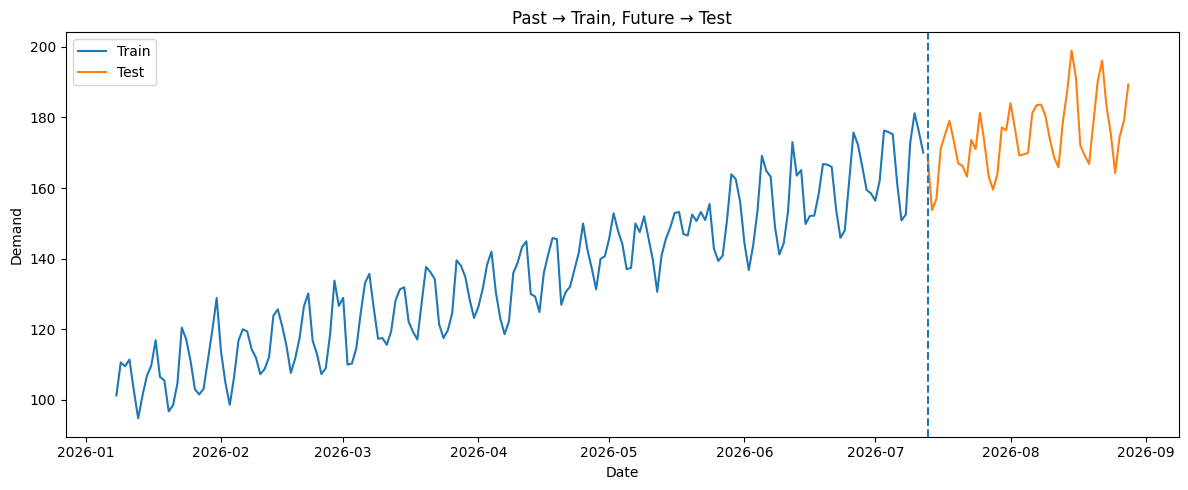

In [6]:
plt.figure(figsize=(12,5))

plt.plot(
    train["date"],
    train["demand"],
    label="Train"
)

plt.plot(
    test["date"],
    test["demand"],
    label="Test"
)

plt.axvline(
    test["date"].iloc[0],
    linestyle="--"
)

plt.xlabel("Date")
plt.ylabel("Demand")
plt.title("Past → Train, Future → Test")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Forecast the held-out future period

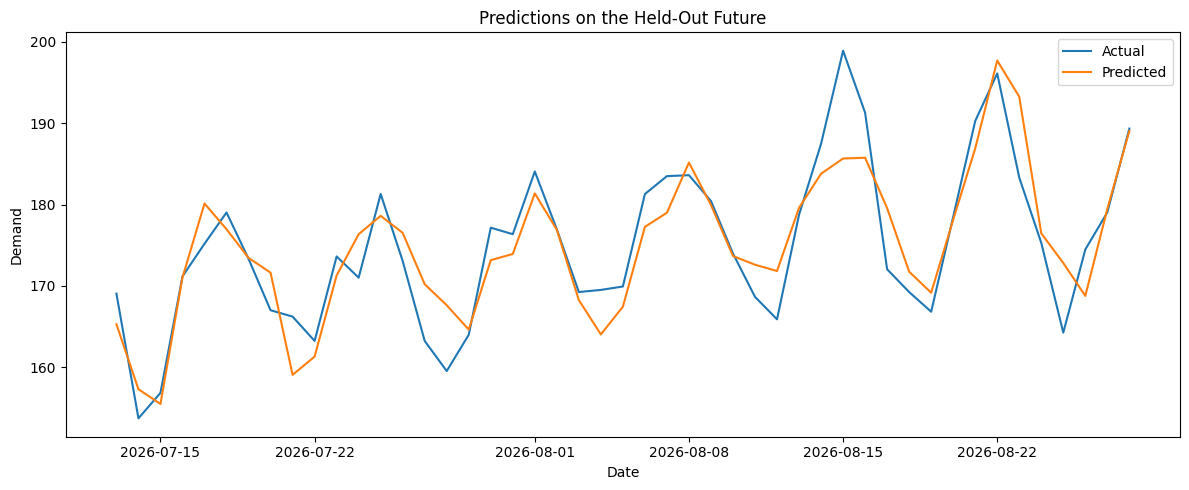

In [7]:
plt.figure(figsize=(12,5))

plt.plot(
    test["date"],
    y_test_time.values,
    label="Actual"
)

plt.plot(
    test["date"],
    time_pred,
    label="Predicted"
)

plt.xlabel("Date")
plt.ylabel("Demand")
plt.title("Predictions on the Held-Out Future")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Compare the two evaluation approaches

In [8]:
comparison=pd.DataFrame({
    "Split Method":[
        "Random Split",
        "Chronological Split"
    ],
    "MAE":[
        random_mae,
        time_mae
    ]
})

display(comparison.round(3))


,Split Method,MAE
0,Random Split,4.358
1,Chronological Split,3.513


## 8. Walk-forward validation with TimeSeriesSplit

A single chronological split gives us only one view of performance.

`TimeSeriesSplit` repeatedly trains on earlier observations and validates on later observations.


In [9]:
tscv=TimeSeriesSplit(n_splits=5)

results=[]

for fold,(train_idx,val_idx) in enumerate(
    tscv.split(X),
    start=1
):
    X_train=X.iloc[train_idx]
    X_val=X.iloc[val_idx]

    y_train=y.iloc[train_idx]
    y_val=y.iloc[val_idx]

    model=LinearRegression()
    model.fit(X_train,y_train)

    pred=model.predict(X_val)

    results.append({
        "Fold":fold,
        "Train Rows":len(train_idx),
        "Validation Rows":len(val_idx),
        "MAE":mean_absolute_error(y_val,pred)
    })

display(pd.DataFrame(results).round(3))


,Fold,Train Rows,Validation Rows,MAE
0,1,43,38,3.769
1,2,81,38,3.597
2,3,119,38,4.111
3,4,157,38,3.956
4,5,195,38,3.623


## 9. Leakage can happen during feature engineering too

A correct chronological split is not enough if the features themselves use future information.

That is why our moving average used:

`shift(1).rolling(7).mean()`

instead of including today's target value.


## Enterprise intuition

This rule matters in:

- demand forecasting
- inventory planning
- infrastructure forecasting
- transaction-volume forecasting
- sensor analytics
- staffing and workload forecasting

A production forecasting model only knows the past when it predicts the future.


## What does this teach?

- Random splitting can be misleading for forecasting.
- Training data should generally precede test data in time.
- Feature engineering must avoid future leakage too.
- Chronological holdout is a useful baseline.
- `TimeSeriesSplit` provides walk-forward validation.
- Evaluation should match real production use.

> **A forecasting model should be tested the same way it will live: learn from the past, predict the future.**


## References

- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html
- https://scikit-learn.org/stable/modules/cross_validation.html
- https://otexts.com/fpp3/tscv.html
